In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
import matplotlib
import scipy as sp
from sklearn.linear_model import LogisticRegression
import util
from cycler import cycler
import seaborn as sns
import matplotlib.patheffects as pe

from scipy.stats import qmc
from numpy.random import Generator, PCG64
import matplotlib.colors as mc
import colorsys

from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from mpl_toolkits.basemap import Basemap
import matplotlib as mpl
import tqdm

import scipy.stats as st
from pathlib import Path
from matplotlib.patches import ConnectionPatch
plt.rcParams.update({'font.size': 12})

In [2]:
TEs = ['AMAZ', 'AMOC', 'ASI', 'ENSO', 'GIS', 'PERM', 'REEF', 'WAIS', 'WAM']
TE_abb = {te:te for te in TEs}
TE_abb['GIS'] = 'GIS-TE'
TE_abb['WAIS'] = 'WAIS-TE'
TE_abb['ASI'] = 'ASI-TE'
TE_abb['REEF'] = 'REEF-TE'

# Illustrative geographical network (Fig. 1)

In [4]:
%run DataProcessingTE.py
# Outputs the following:
    # df_AM22 - processed individual TE data from Armstrong McKay et al 2022
    # df_W24 - TE-TE interactions from Wunderling et al 2024
    # df_SSPs - global mean surface temp. anomalies vs pre-industrial (1850-1900). Historical and several SSPs
        # See scenarios for the list of scenarios 

/home/jbara/Documents/Code/test-env/Notebooks/DataProcessingTE.py:21: RuntimeWarning: Mean of empty slice
  return np.exp(np.nanmean(np.log([minstr,maxstr])))


/tmp/ipykernel_79874/3426976135.py:62: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cbar.ax.set_xticklabels([str(r)+'℃' for r in range(1,8)]);


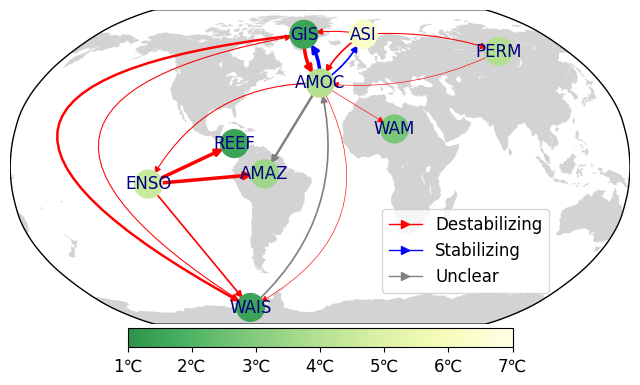

In [11]:
G = nx.from_pandas_edgelist(df_W24,source='Source',target='Target',edge_attr=['Dist. Min.', 'Dist. Max.'],create_using=nx.DiGraph)
m = Basemap(projection='robin',lon_0=-30,resolution='c');
pos_lonlat = {'GIS':[-43,70], 'AMOC':[-30,43],'ENSO':[-130,-8.8],
              'WAIS':[-90,-75],'ASI':[5,70],'PERM':[100,60],
              'WAM':[14,19.5],'REEF':[-80,12],'AMAZ':[-62.2,-3.5]}
pos_xy ={k:m(v[0],v[1]) for k,v in pos_lonlat.items()}
T_lim_dic = df_AM22['Threshold (°C) - Est.'].to_dict()
T_lim_dic['ENSO'] = 4.5

fig,ax=plt.subplots(figsize=(8,5))

elist = [(e[0],e[1],0) for e in G.edges]
earc_dic = {e:0 for e in G.edges}
earc_dic[('GIS','AMOC')]=0.2
earc_dic[('AMOC','GIS')]=0.2
earc_dic[('AMOC','WAIS')]=-0.5
earc_dic[('AMOC','ENSO')]=0.3
earc_dic[('WAIS','AMOC')]=0.3
earc_dic[('ASI','AMOC')]=0.15
earc_dic[('AMOC','ASI')]=0.15
earc_dic[('ASI','GIS')]=0.1
earc_dic[('PERM','AMOC')]=-0.15
earc_dic[('ASI','PERM')]=-0.1
earc_dic[('WAIS','GIS')]=-1.3
earc_dic[('GIS','WAIS')]=1.6
# e_man_list = [('GIS','WAIS'),('WAIS','GIS'),('ASI','GIS'),('AMOC','WAIS')]
# for e in e_man_list:
#     elist.remove(e)
# m.drawcoastlines();
m.fillcontinents(color='lightgray',lake_color='white');
# x,y = m(pos['GIS'][0],pos['GIS'][1])
prop_cycle = plt.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']

nx.draw_networkx(G,ax=ax,pos=pos_xy,node_size=400,with_labels=True,edgelist=[],
                 node_color=[T_lim_dic[n] for n in G.nodes()],
                 vmin=-1.5,vmax=7,
                 cmap='YlGn_r',font_size=12,font_color='navy',font_weight=None)
for e in G.edges:
    vals = G.get_edge_data(e[0],e[1])
    if vals['Dist. Min.'] > 0: # Destabilising
        c = 'r'
        w = vals['Dist. Max.']
    elif vals['Dist. Max.'] < 0: # Stabilising
        c = 'b'
        w= np.abs(vals['Dist. Min.'])
    else: # Unclear
        c = 'gray' 
        w = vals['Dist. Max.']
    nx.draw_networkx_edges(G,pos_xy,ax=ax,edgelist=[e], 
                           edge_color=c, width=np.log(w)*1.1,
                           connectionstyle="arc3,rad=rrr".replace('rrr',str(earc_dic[e])));

custom_lines = [Line2D([0], [0], color='r', lw=1, marker='>'),
                Line2D([0], [0], color='b', lw=1, marker='>'),
                Line2D([0], [0], color='gray', lw=1, marker='>')]
ax.legend(custom_lines,['Destabilizing','Stabilizing', 'Unclear'],loc=[0.6,0.1])
# fig.colorbar(im,ax=ax)
cbar = fig.colorbar(mpl.cm.ScalarMappable(cmap='YlGn_r',norm=mpl.colors.Normalize(vmin=-1.5,vmax=7)), 
             ax=ax, orientation='horizontal',fraction=0.05,pad=0.01)
cbar.ax.set_xlim([1,7])
cbar.ax.set_xticklabels([str(r)+'℃' for r in range(1,8)]);

fig.savefig('../Figures/TE_network.png',format='png',bbox_inches='tight',dpi=300)

# Historical/SSP Warming

In [3]:
years = np.arange(1950, 2100) 
SSPs = ['SSP1_1_9', 'SSP1_2_6', 'SSP2_4_5', 'SSP3_7_0', 'SSP5_8_5']
# Loading data from relevant csv
valmin_str='0001'
Nico_times=True
if Nico_times:
    folder = "../Data/Simulations/TE/Sigmoid/"+valmin_str+"_at_Tmin_NWrtimes/SSP Warming/"
    folder_out = "../Figures/TE (sigmoid)/"+valmin_str+"_at_Tmin_NWrtimes/"
else:
    folder = "../Data/Simulations/TE/Sigmoid/"+valmin_str+"_at_Tmin_WBrtimes/SSP Warming/"
    folder_out = "../Figures/TE (sigmoid)/"+valmin_str+"_at_Tmin_WBrtimes/"
Path(folder_out[:-1]).mkdir(parents=True, exist_ok=True)

D_hist = np.array([np.loadtxt(folder+'D_%s_Historical.csv'%te) for te in TEs])
D_ssps = np.array([[np.loadtxt(folder+'D_%s_%s.csv'%(te,ssp)) for te in TEs] for ssp in SSPs])
D_noint = np.array([[np.loadtxt(folder+'D_no_interaction_%s_%s.csv'%(te,ssp)) for te in TEs] for ssp in SSPs])

In [4]:
fpath = '../Data/IPCC AR6 Warming Data/tas_global_'
scenarios = ['Historical',
            'SSP1_1_9',
            'SSP1_2_6',
            'SSP2_4_5',
            'SSP3_7_0',
            'SSP5_8_5']
df_SSPs = {s:pd.read_csv(fpath+s+'.csv') for s in scenarios}

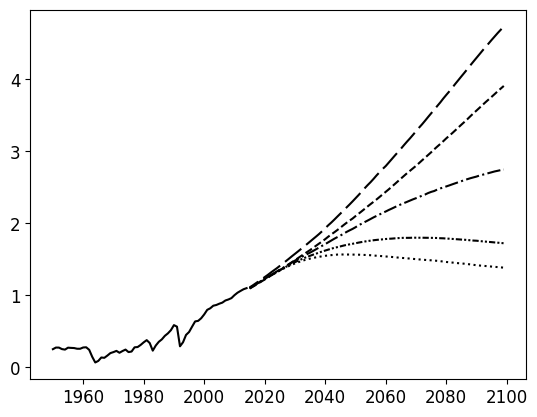

In [6]:
linestyles = ['-',':',(0, (3, 1, 1, 1, 1, 1)),'-.','--',(5,(10,3))]
for i,s in enumerate(scenarios):
    # plt.fill_between(df_SSPs[s]['Year'],
    #                  df_SSPs[s]['5%'],
    #                  df_SSPs[s]['95%'],alpha=0.5)
    plt.plot(df_SSPs[s]['Year'],df_SSPs[s]['Mean'],color='k',ls=linestyles[i])

## Evolution 1950-2100 (Fig. 4)

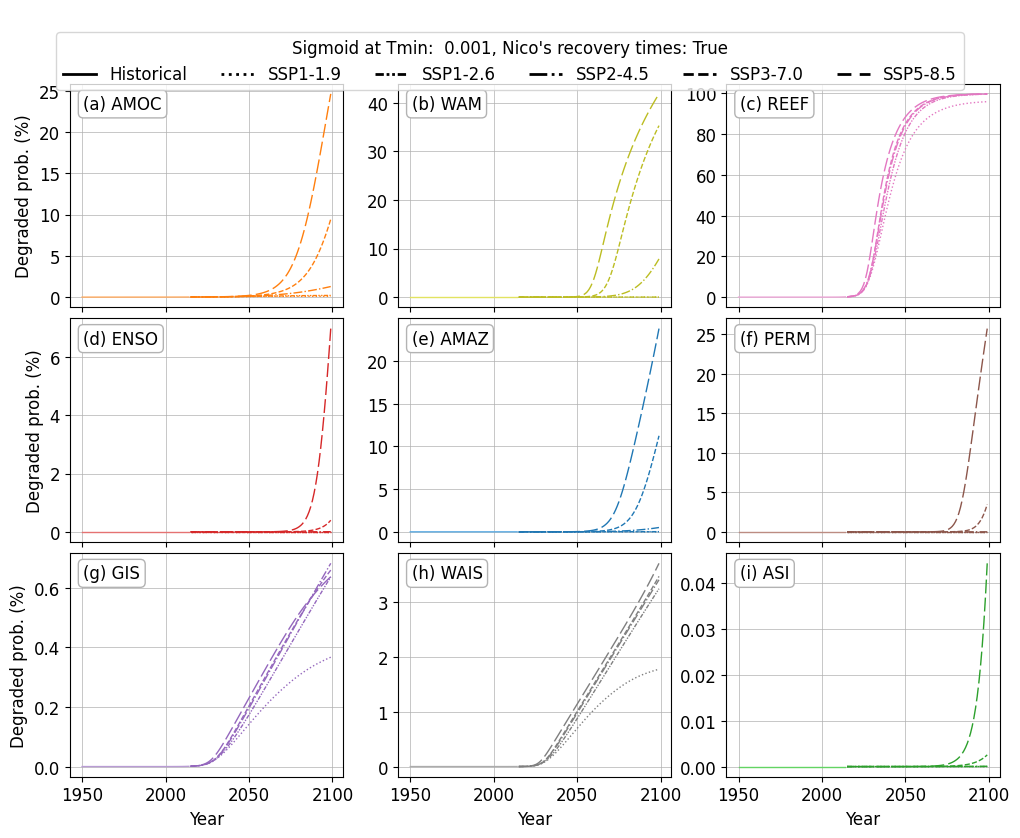

In [110]:
fig,axs = plt.subplots(figsize=(12,9),nrows=3,ncols=3,sharex=True,sharey=False)
fig.subplots_adjust(hspace=0.05) # hspace=0.05

prop_cycle = plt.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']
linestyles = [':',(0, (3, 1, 1, 1, 1, 1)),'-.','--',(5,(10,3))]
scen_labels = ['SSP1-1.9', 'SSP1-2.6', 'SSP2-4.5', 'SSP3-7.0', 'SSP5-8.5']

TE_ordered = ['AMOC', 'WAM', 'REEF',
              'ENSO', 'AMAZ','PERM',
              'GIS', 'WAIS', 'ASI']
letters = ['(%s)'%l for l in 'abcdefghi']
TE_ind = {te:i for i,te in enumerate(TEs)}
for i_ax,te in enumerate(TE_ordered):
    i = TE_ind[te]
    axs[i_ax//3,i_ax%3].annotate(letters[i_ax] + ' '+ TEs[i],(0.05,0.95),
                                 xycoords='axes fraction',ha='left',va='top',fontsize=12,
                                 bbox=dict(fc='white',edgecolor='0.7',boxstyle='round'))
    # axs[i_ax//3,i_ax%3].fill_between(years[:D_hist.shape[-1]], 
    #                                  np.quantile(D_hist[i,:,:]*100,0.05,axis=0),
    #                                  np.quantile(D_hist[i,:,:]*100,0.95,axis=0),
    #                                  color=util.lighten_color(colors[i],0.3),
    #                                  edgecolor=util.lighten_color(colors[i],0.3),
    #                                  alpha=1)
    # axs[i_ax//3,i_ax%3].fill_between(years[:D_hist.shape[-1]], 
    #                                  np.quantile(D_hist[i,:,:]*100,0.25,axis=0),
    #                                  np.quantile(D_hist[i,:,:]*100,0.75,axis=0),
    #                                  color=util.lighten_color(colors[i],0.65),
    #                                  edgecolor=util.lighten_color(colors[i],0.65),
    #                                  alpha=1)
    axs[i_ax//3,i_ax%3].plot(years[:D_hist.shape[-1]],D_hist[i,:,:].mean(axis=0)*100,
                       c=util.lighten_color(colors[i],0.65), 
                       ls='-',lw=1)
    axs[i_ax//3,i_ax%3].grid(visible=True,lw=0.5,axis='both')
    for j in range(len(SSPs)):
        # axs[i_ax//3,i_ax%3].fill_between(years[D_hist.shape[-1]:], 
        #                              np.quantile(D_ssps[j,i,:,:]*100,0.05,axis=0),
        #                              np.quantile(D_ssps[j,i,:,:]*100,0.95,axis=0),
        #                              color=util.lighten_color(colors[i],0.3),
        #                              edgecolor=util.lighten_color(colors[i],0.3),
        #                              alpha=1)
        # axs[i_ax//3,i_ax%3].fill_between(years[D_hist.shape[-1]:], 
        #                              np.quantile(D_ssps[j,i,:,:]*100,0.25,axis=0),
        #                              np.quantile(D_ssps[j,i,:,:]*100,0.75,axis=0),
        #                              color=util.lighten_color(colors[i],0.65),
        #                              edgecolor=util.lighten_color(colors[i],0.65),
        #                              alpha=1)
        axs[i_ax//3,i_ax%3].plot(years[D_hist.shape[-1]:],D_ssps[j,i,:,:].mean(axis=0)*100,
                           c=colors[i], ls=linestyles[j],
                           lw=1)

lines=[Line2D([0], [0], color='k', lw=2, label='Historical')] 
lines += [Line2D([0], [0], color='k', lw=2, 
                 label=scen_labels[j], ls = linestyles[j]) for j in range(5)]

for i in range(3):
    axs[-1,i].set_xlabel('Year')
    axs[i,0].set_ylabel('Degraded prob. (%)')

# fig.legend(handles=lines,ncols=6,loc='upper center',
#            prop={'size':12},borderaxespad=2)
# fig.savefig(folder_out+'TE_D_initP_interactions.pdf',format='pdf',dpi=300,bbox_inches='tight')

# fig.legend(handles=lines,ncols=6,loc='upper center',
#            prop={'size':12},borderaxespad=2,
#            title='Sigmoid at Tmin: '+' 0.'+valmin_str[1:]+", Nico's recovery times: "+str(Nico_times))
# fig.savefig("../Figures/"+valmin_str+'NW'+str(Nico_times)+'TE_D_initP_interactions.pdf',format='pdf',bbox_inches='tight')

## Distribution in 2100 (Fig. 5)

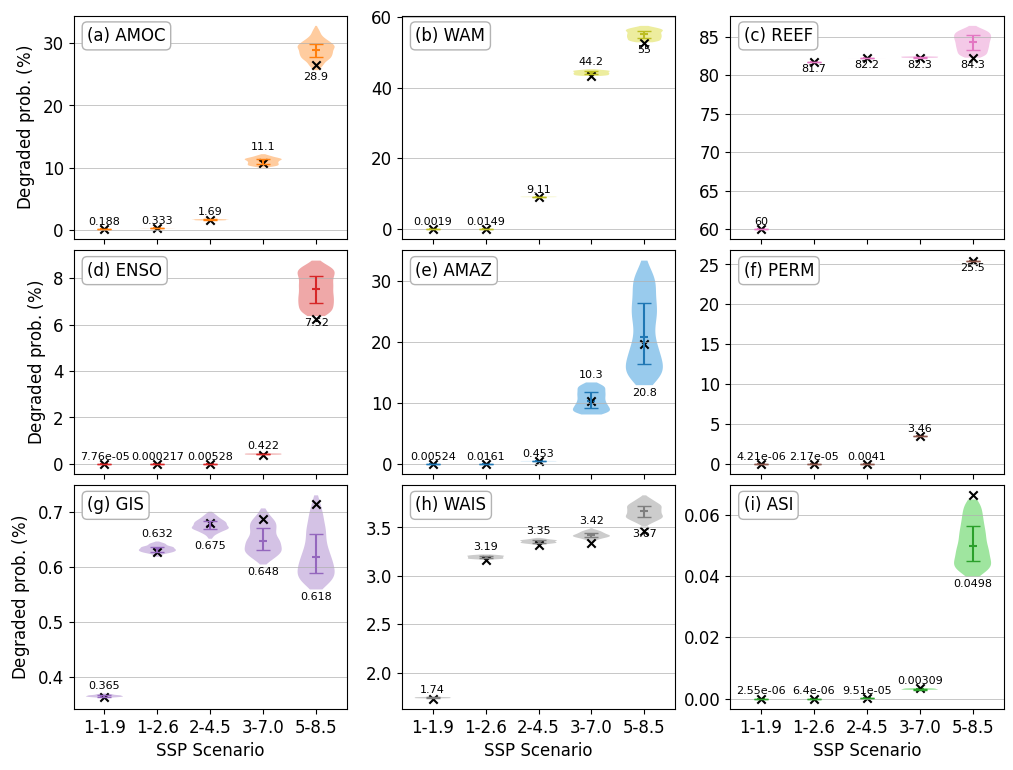

In [65]:
TE_ordered = ['AMOC', 'WAM', 'REEF',
              'ENSO', 'AMAZ','PERM',
              'GIS', 'WAIS', 'ASI']
letters = ['(%s)'%l for l in 'abcdefghi']
TE_ind = {te:i for i,te in enumerate(TEs)}

fig,axs = plt.subplots(figsize=(12,9),nrows=3,ncols=3,sharex=True,sharey=False)
fig.subplots_adjust(hspace=0.05)

prop_cycle = plt.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']
linestyles = [':',(0, (3, 1, 1, 1, 1, 1)),'-.','--',(5,(10,3))]
scen_labels = ['SSP1-1.9', 'SSP1-2.6', 'SSP2-4.5', 'SSP3-7.0', 'SSP5-8.5']

parts = []
for i_ax,te in enumerate(TE_ordered):
    i = TE_ind[te]
    data = [D_ssps[j,i,:,-1]*100 for j in range(5)]

    parts.append(axs[i_ax//3,i_ax%3].violinplot(data,showmeans=False, showmedians=False,
        showextrema=False, widths=0.7))
    axs[i_ax//3,i_ax%3].annotate(letters[i_ax] + ' '+TEs[i],(0.05,0.95),xycoords='axes fraction',
                                 ha='left',va='top',fontsize=12,
                                 bbox=dict(fc='white',edgecolor='0.7',boxstyle='round'))

    x= np.arange(1,6)
    y= np.median(data,axis=1)
    yerr = np.abs(np.quantile(data,[0.25,0.75],axis=1)-y)
    # axs[i//3,i%3].scatter(x,np.mean(data,axis=1),marker='_',c='k')
    axs[i_ax//3,i_ax%3].scatter(x,y,color=util.lighten_color(colors[i],1),
                          marker='_')
    axs[i_ax//3,i_ax%3].errorbar(x,y,yerr=yerr,ls='',
                           c=util.lighten_color(colors[i],1),marker='',barsabove=True,capsize=5)
    ylim=axs[i_ax//3,i_ax%3].get_ylim()
    axs[i_ax//3,i_ax%3].grid(visible=True,lw=0.5,axis='y')

    # SANS INTERACTIONS SCATTER
    axs[i_ax//3,i_ax%3].scatter(np.arange(1,6),(100*D_noint[:,i,-1]),marker='x',color='k')
    
    for s in range(5):
        if data[s].max()<= 0.9*np.max(ylim):
            axs[i_ax//3,i_ax%3].annotate('%.3g'%(y[s]),
                                   [s+1,data[s].max()+0.01*(ylim[1]-ylim[0])],
                                   ha='center',va='bottom',fontsize=8)
        else:
            axs[i_ax//3,i_ax%3].annotate('%.3g'%(y[s]),
                                   [s+1,data[s].min()-0.01*(ylim[1]-ylim[0])],
                                   ha='center',va='top',fontsize=8)
    # axs[i//3,i%3].set_yscale('log')
# ax.set_ylabel(r'Degraded probability after 200y')
xlim = axs[0,0].get_xlim()
for j_ax in range(9):
    j = TE_ind[TE_ordered[j_ax]]
    # axs[j//3,j%3].plot([0,6],[D[:,:,j,-1].mean()*100]*2,c='k',ls='--',lw=0.5)
    for i,pc in enumerate(parts[j_ax]['bodies']):
        pc.set_facecolor(util.lighten_color(colors[j],0.4))
        # pc.set_edgecolor('black')
        pc.set_alpha(1)

for i in range(3):
    axs[-1,i].set_xlabel('SSP Scenario')
    axs[i,0].set_ylabel(r'Degraded prob. $(\%)$')

axs[0,0].set_xticks(range(1,6),[s[3:] for s in scen_labels])
axs[0,0].set_xlim(xlim)
fig.savefig(folder_out+'TE_D_violins_2100_initP.pdf',format='pdf',bbox_inches='tight',dpi=300)

In [14]:
D_noint.shape

(5, 9, 85)

# Stationary distribution under fixed warming

## 1.6C (Fig. 2)

In [66]:
valmin_str='0001'
Nico_time = False
if Nico_time:
    folder = "../Data/Simulations/TE/Sigmoid/"+valmin_str+"_at_Tmin_NWrtimes/Fixed 1_6/"
    folder_out = "../Figures/TE (sigmoid)/"+valmin_str+"_at_Tmin_NWrtimes/"
else:
    folder = "../Data/Simulations/TE/Sigmoid/"+valmin_str+"_at_Tmin_WBrtimes/Fixed 1_6/"
    folder_out = "../Figures/TE (sigmoid)/"+valmin_str+"_at_Tmin_WBrtimes/"
Path(folder_out[:-1]).mkdir(parents=True, exist_ok=True)
D_theory = np.loadtxt(folder+"stat_dist.csv")
D_source = np.loadtxt(folder+"stat_dist_no_interactions.csv")

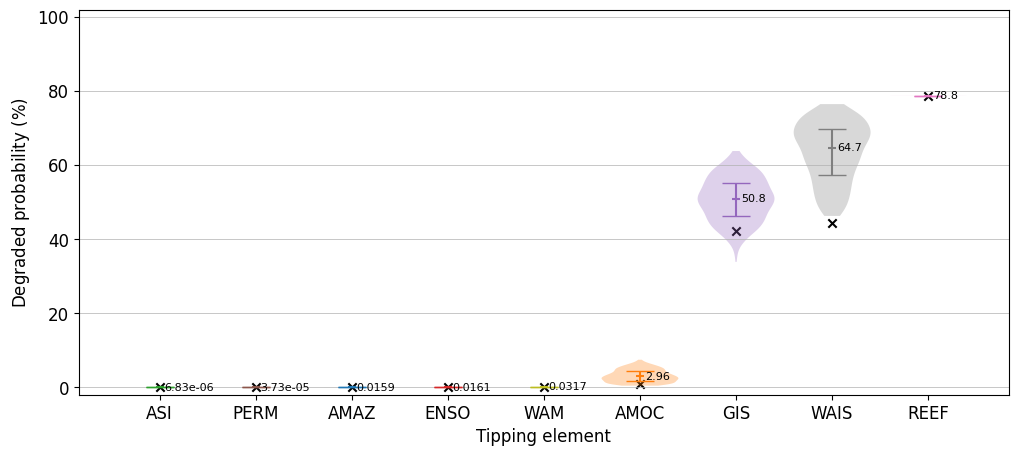

In [67]:
fig,ax = plt.subplots(figsize=(12,5))
prop_cycle = plt.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']
y= np.median(D_theory,axis=0)*100
yerr = np.abs(np.quantile(D_theory*100,[0.25,0.75],axis=0)-y)
full = sorted(zip(list(y),TEs,range(9)))

ax.scatter(np.arange(1,10),[100*D_source[i] for _,_,i in full],marker='x',color='k')
for i in range(9):
    i_ax=full[i][2]
    vp=ax.violinplot(D_theory[:,i_ax]*100,positions=[i+1],showmeans=False, showmedians=False,
        showextrema=False, widths=0.8)
    for b in vp['bodies']:
        b.set_facecolor(colors[i_ax])
    ax.scatter([i+1],y[i_ax],color=util.lighten_color(colors[i_ax],1),marker='_')
    ax.errorbar([i+1],y[i_ax],yerr=yerr[:,i_ax].reshape(2,1),ls='',ecolor=util.lighten_color(colors[i_ax],1),
                marker='',barsabove=True,capsize=10)
    # if i > 1:
    ax.annotate('%.3g'%(y[i_ax]),[i+1.05,y[i_ax]],ha='left',va='center',fontsize=8)

plt.xticks(np.arange(1,10), [te for _,te,_ in full]);
plt.ylabel(r"Degraded probability ($\%$)")
plt.xlabel("Tipping element")
ax.grid(visible=True,lw=0.5,axis='y')
ax.set_ylim([-2,102])

# subregions = [(0.5,1.5,0.4,1.6), (1.5,2.5,2.915,3.005)]
# axins = [ax.inset_axes([0.5+i, 65, 1, 30],transform=ax.transData, xlim=(sr[0], sr[1]), ylim=(sr[2], sr[3])) for i,sr in enumerate(subregions)]
# for i in range(2):   
#     axins[i].set_xticks([])
#     i_ax=full[i][2]
#     vp=axins[i].violinplot(D_theory[:,i_ax]*100,positions=[i+1],showmeans=False, showmedians=False,
#         showextrema=False, widths=0.8)
#     for b in vp['bodies']:
#         b.set_facecolor(colors[i_ax])
#     axins[i].scatter([i+1],y[i_ax],color=util.lighten_color(colors[i_ax],1),marker='_')
#     axins[i].scatter(i+1,(100*D_source)[i_ax],marker='x',color='k')
#     axins[i].errorbar([i+1],y[i_ax],yerr=yerr[:,i_ax].reshape(2,1),ls='',ecolor=util.lighten_color(colors[i_ax],1),
#                 marker='',barsabove=True,capsize=10)
#     axins[i].annotate('%.3g'%(y[i_ax]),[i+1.05,y[i_ax]],ha='left',va='center',fontsize=8)

# axins[0].tick_params(axis="y",direction="in", labelsize=8,pad=1)
# axins[1].tick_params(axis="y",direction="in", labelsize=8,pad=1)
# axins[1].yaxis.tick_right()

# axins[0].annotate('(a)',(0.1,0.95),xycoords='axes fraction',
#                                      ha='left',va='top',fontsize=10)
# axins[1].annotate('(b)',(0.1,0.95),xycoords='axes fraction',
                                     # ha='left',va='top',fontsize=10)

fig.savefig(folder_out+'TE_D_stat_dist.png',format='png',bbox_inches='tight',dpi=300)

In [72]:
print(TEs)

['AMAZ', 'AMOC', 'ASI', 'ENSO', 'GIS', 'PERM', 'REEF', 'WAIS', 'WAM']


## Global warming 0 - 10 (Fig. 3)

In [19]:
valmin_str='0001'
Nico_time = False
if Nico_time:
    folder = "../Data/Simulations/TE/Sigmoid/"+valmin_str+"_at_Tmin_NWrtimes/Stat dist over GMST/"
    folder_out = "../Figures/TE (sigmoid)/"+valmin_str+"_at_Tmin_NWrtimes/"
else:
    folder = "../Data/Simulations/TE/Sigmoid/"+valmin_str+"_at_Tmin_WBrtimes/Stat dist over GMST/"
    folder_out = "../Figures/TE (sigmoid)/"+valmin_str+"_at_Tmin_WBrtimes/"
Path(folder_out[:-1]).mkdir(parents=True, exist_ok=True)

D_theory = np.array([np.loadtxt(folder+"D_"+te+".csv") 
                     for i,te in enumerate(TEs)]).transpose((1,2,0))
D_theory_noint = np.array([np.loadtxt(folder+"D_no_interaction_"+te+".csv") 
                           for i,te in enumerate(TEs)]).transpose()
T = np.arange(0,10,step=0.001)

In [13]:
D_theory.shape

(500, 10000, 9)

In [20]:
%run DataProcessingTE.py
# Outputs the following:
    # df_AM22 - processed individual TE data from Armstrong McKay et al 2022
    # df_W24 - TE-TE interactions from Wunderling et al 2024
    # df_SSPs - global mean surface temp. anomalies vs pre-industrial (1850-1900). Historical and several SSPs
        # See scenarios for the list of scenarios 
T_lim = np.array(df_AM22['T_lim'].to_list())

/home/jbara/Documents/Code/test-env/Notebooks/DataProcessingTE.py:21: RuntimeWarning: Mean of empty slice
  return np.exp(np.nanmean(np.log([minstr,maxstr])))


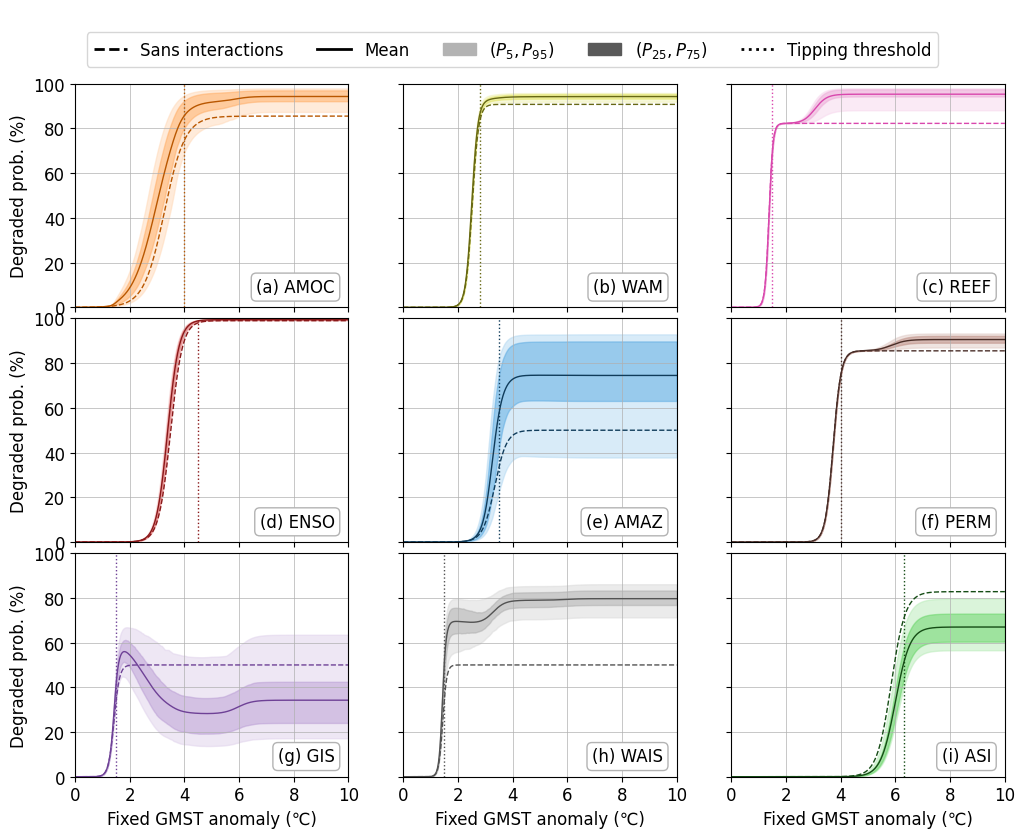

In [22]:
T = np.arange(0,10,step=0.001)
fig,axs = plt.subplots(figsize=(12,9),nrows=3,ncols=3,sharex=True,sharey=True)
fig.subplots_adjust(hspace=0.05)

prop_cycle = plt.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']
# linestyles = [':',(0, (3, 1, 1, 1, 1, 1)),'-.','--',(5,(10,3))]
# scen_labels = ['SSP1-1.9', 'SSP1-2.6', 'SSP2-4.5', 'SSP3-7.0', 'SSP5-8.5']

TE_ordered = ['AMOC', 'WAM', 'REEF',
              'ENSO', 'AMAZ','PERM',
              'GIS', 'WAIS', 'ASI']
letters = ['(%s)'%l for l in 'abcdefghi']

ann_ind = {0:1, 1:1, 2:1, 3:1, 7:1, 
           4:1, 5:1, 6:1, 8:1}
locs = [(0.05,0.95),(0.95,0.05)]
has = ['left','right']
vas = ['top','bottom']
TE_ind = {te:i for i,te in enumerate(TEs)}
for i_ax,te in enumerate(TE_ordered):
    i = TE_ind[te]
    # axs[i_ax//3,i_ax%3].plot([1.2,1.2],[0,100],c='k')
    axs[i_ax//3,i_ax%3].grid(visible=True,lw=0.5,axis='both')
    axs[i_ax//3,i_ax%3].annotate(letters[i_ax] + ' '+ TEs[i],locs[ann_ind[i_ax]],
                                 xycoords='axes fraction',
                                 ha=has[ann_ind[i_ax]],
                                 va=vas[ann_ind[i_ax]],
                                 fontsize=12,
                                 bbox=dict(fc='white',
                                           edgecolor='0.7',
                                           boxstyle='round'))
    axs[i_ax//3,i_ax%3].plot([T_lim[i]]*2,[0,100],c=util.lighten_color(colors[i],1.35),ls=':',lw=1)

    # for r in range(500):
    #     axs[i_ax//3,i_ax%3].plot(T,D_theory[r,:,i]*100,
    #                              c=colors[i], 
    #                              ls='-',lw=0.01)
    axs[i_ax//3,i_ax%3].fill_between(T, 
                                     np.quantile(D_theory[:,:,i]*100,0.05,axis=0),
                                     np.quantile(D_theory[:,:,i]*100,0.95,axis=0),
                                     color=util.lighten_color(colors[i],0.3),
                                     edgecolor=util.lighten_color(colors[i],0.3),
                                     alpha=0.5)
    axs[i_ax//3,i_ax%3].fill_between(T, 
                                     np.quantile(D_theory[:,:,i]*100,0.25,axis=0),
                                     np.quantile(D_theory[:,:,i]*100,0.75,axis=0),
                                     color=util.lighten_color(colors[i],0.65),
                                     edgecolor=util.lighten_color(colors[i],0.65),
                                     alpha=0.5)
    axs[i_ax//3,i_ax%3].plot(T,D_theory[:,:,i].mean(axis=0)*100,
                             c=util.lighten_color(colors[i],1.35), 
                             ls='-',lw=1)

    axs[i_ax//3,i_ax%3].plot(T,D_theory_noint[:,i]*100,
                             c=util.lighten_color(colors[i],1.35), 
                             ls='--',lw=1)

lines=[
       Line2D([0], [0], color='k', lw=2, label='Sans interactions',ls='--'),
       Line2D([0], [0], color='k', lw=2, label='Mean'),
       Patch(facecolor=util.lighten_color('k',0.3), 
             edgecolor=util.lighten_color('k',0.3), label='$(P_5,P_{95})$'),
       Patch(facecolor=util.lighten_color('k',0.65), 
             edgecolor=util.lighten_color('k',0.65), label='$(P_{25},P_{75})$'),
    Line2D([0], [0], color='k', lw=2, label='Tipping threshold',ls=':')] 
# lines += [Line2D([0], [0], color='k', lw=2, 
#                  label=scen_labels[j], ls = linestyles[j]) for j in range(5)]


# fig.text(0.5, 0.04, 'Fixed GMST anomaly (℃)', ha='center')
# fig.text(0.04, 0.5, 'Stationary degraded prob. (%)', va='center', rotation='vertical')
for i in range(3):
    axs[-1,i].set_xlabel('Fixed GMST anomaly (℃)')
    axs[i,0].set_ylabel('Degraded prob. (%)')

axs[0,0].set_xlim([0,10])
axs[0,0].set_ylim([0,100])

fig.legend(handles=lines,ncols=6,loc='upper center',prop={'size':12},borderaxespad=2)
fig.savefig(folder_out+'TE_D_stat_dist_GMSTs.png',format='png',bbox_inches='tight',dpi=300)

# fig.legend(handles=lines,ncols=6,loc='upper center',
#            prop={'size':12},borderaxespad=2,
#            title='Sigmoid at Tmin: '+' 0.'+valmin_str[1:]+", Nico's recovery times: "+str(Nico_time))
# fig.savefig("../Figures/"+valmin_str+'NW'+str(Nico_time)+'GMST_individual.pdf',format='pdf',bbox_inches='tight')

In [11]:
print(TEs)

['AMAZ', 'AMOC', 'ASI', 'ENSO', 'GIS', 'PERM', 'REEF', 'WAIS', 'WAM']


(1.5, 2.0)

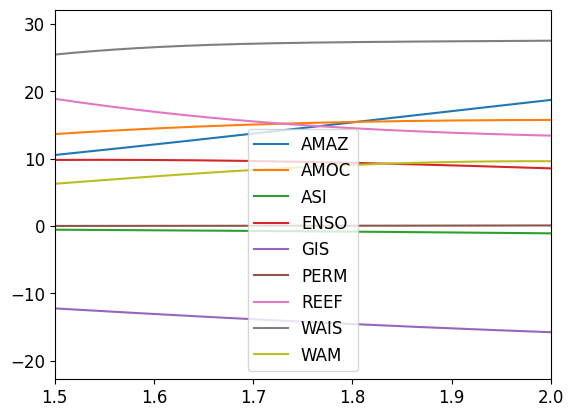

In [25]:
# plt.plot(T,(D_theory_noint[:,2]-D_theory[:,:,2].mean(axis=0))*100,label='ASI')
# plt.plot(T,(D_theory_noint[:,4]-D_theory[:,:,4].mean(axis=0))*100,label='GIS')
for i,te in enumerate(TEs):
    plt.plot(T,(D_theory[:,:,i].mean(axis=0)-D_theory_noint[:,i])*100,label=te)
plt.legend()
plt.xlim([1.5,2])

In [20]:
D_theory.shape

(500, 10000, 9)

# Supplementary Figures

## SSP increase wrt sans interaction (Fig. S2)

In [69]:
years = np.arange(1950, 2100) 
SSPs = ['SSP1_1_9', 'SSP1_2_6', 'SSP2_4_5', 'SSP3_7_0', 'SSP5_8_5']
# Loading data from relevant csv
valmin_str='0001'
Nico_times=False
if Nico_times:
    folder = "../Data/Simulations/TE/Sigmoid/"+valmin_str+"_at_Tmin_NWrtimes/SSP Warming/"
    folder_out = "../Figures/TE (sigmoid)/"+valmin_str+"_at_Tmin_NWrtimes/"
else:
    folder = "../Data/Simulations/TE/Sigmoid/"+valmin_str+"_at_Tmin_WBrtimes/SSP Warming/"
    folder_out = "../Figures/TE (sigmoid)/"+valmin_str+"_at_Tmin_WBrtimes/"
Path(folder_out[:-1]).mkdir(parents=True, exist_ok=True)
# folder = "../Data/Simulations/TE/SSP Warming/"
D_hist = np.array([np.loadtxt(folder+'D_%s_Historical.csv'%te) for te in TEs])
D_ssps = np.array([[np.loadtxt(folder+'D_%s_%s.csv'%(te,ssp)) for te in TEs] for ssp in SSPs])
D_nointH = np.array([np.loadtxt(folder+'D_no_interaction_%s_Historical.csv'%(te)) for te in TEs])
D_nointSSP = np.array([[np.loadtxt(folder+'D_no_interaction_%s_%s.csv'%(te,ssp)) for te in TEs] for ssp in SSPs])

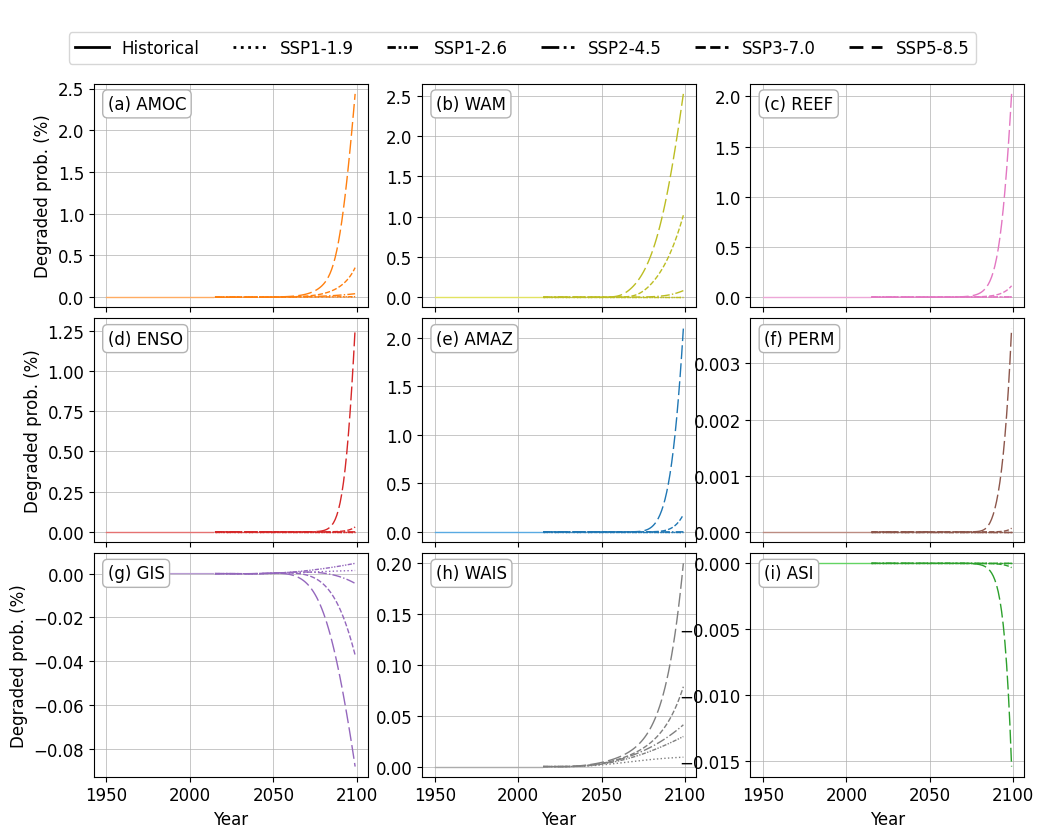

In [70]:
fig,axs = plt.subplots(figsize=(12,9),nrows=3,ncols=3,sharex=True,sharey=False)
fig.subplots_adjust(hspace=0.05) # hspace=0.05

prop_cycle = plt.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']
linestyles = [':',(0, (3, 1, 1, 1, 1, 1)),'-.','--',(5,(10,3))]
scen_labels = ['SSP1-1.9', 'SSP1-2.6', 'SSP2-4.5', 'SSP3-7.0', 'SSP5-8.5']

TE_ordered = ['AMOC', 'WAM', 'REEF',
              'ENSO', 'AMAZ','PERM',
              'GIS', 'WAIS', 'ASI']
letters = ['(%s)'%l for l in 'abcdefghi']
TE_ind = {te:i for i,te in enumerate(TEs)}
for i_ax,te in enumerate(TE_ordered):
    i = TE_ind[te]
    axs[i_ax//3,i_ax%3].annotate(letters[i_ax] + ' '+ TEs[i],(0.05,0.95),
                                 xycoords='axes fraction',ha='left',va='top',fontsize=12,
                                 bbox=dict(fc='white',edgecolor='0.7',boxstyle='round'))
    axs[i_ax//3,i_ax%3].plot(years[:D_hist.shape[-1]],D_hist[i,:,:].mean(axis=0)*100-D_nointH[i,:]*100,
                       c=util.lighten_color(colors[i],0.65), 
                       ls='-',lw=1)
    axs[i_ax//3,i_ax%3].grid(visible=True,lw=0.5,axis='both')
    for j in range(len(SSPs)):
        axs[i_ax//3,i_ax%3].plot(years[D_hist.shape[-1]:],D_ssps[j,i,:,:].mean(axis=0)*100-D_nointSSP[j,i,:]*100,
                           c=colors[i], ls=linestyles[j],
                           lw=1)

lines=[Line2D([0], [0], color='k', lw=2, label='Historical')] 
lines += [Line2D([0], [0], color='k', lw=2, 
                 label=scen_labels[j], ls = linestyles[j]) for j in range(5)]
fig.legend(handles=lines,ncols=6,loc='upper center',prop={'size':12},borderaxespad=2)

for i in range(3):
    axs[-1,i].set_xlabel('Year')
    axs[i,0].set_ylabel('Degraded prob. (%)')

fig.savefig(folder_out+'TE_D_initP_int_minus_noint.pdf',format='pdf',dpi=300,bbox_inches='tight')

# The Earth system as a whole

## Short term (Fig. S3)

In [4]:
years = np.arange(1950, 2100) 
SSPs = ['SSP1_1_9', 'SSP1_2_6', 'SSP2_4_5', 'SSP3_7_0', 'SSP5_8_5']
SSP_labs = ['1-1.9', '1-2.6', '2-4.5', '3-7.0', '5-8.5']
# Loading data from relevant csv
valmin_str='0001'
Nico_times=True
if Nico_times:
    folder = "../Data/Simulations/TE/Sigmoid/"+valmin_str+"_at_Tmin_NWrtimes/SSP Warming/"
    folder_out = "../Figures/TE (sigmoid)/"+valmin_str+"_at_Tmin_NWrtimes/"
else:
    folder = "../Data/Simulations/TE/Sigmoid/"+valmin_str+"_at_Tmin_WBrtimes/SSP Warming/"
    folder_out = "../Figures/TE (sigmoid)/"+valmin_str+"_at_Tmin_WBrtimes/"
Path(folder_out[:-1]).mkdir(parents=True, exist_ok=True)

D_hist = np.array([np.loadtxt(folder+'D_%s_Historical.csv'%te) for te in TEs])
D_ssps = np.array([[np.loadtxt(folder+'D_%s_%s.csv'%(te,ssp)) for te in TEs] for ssp in SSPs])
D_nointH = np.array([np.loadtxt(folder+'D_no_interaction_%s_Historical.csv'%(te)) for te in TEs])
D_nointSSP = np.array([[np.loadtxt(folder+'D_no_interaction_%s_%s.csv'%(te,ssp)) for te in TEs] for ssp in SSPs])

In [5]:
D_ssps.shape

(5, 9, 500, 85)

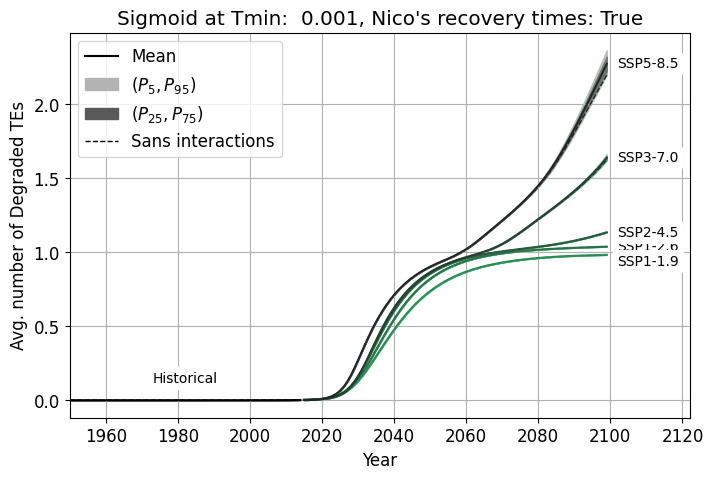

In [7]:
fig,ax = plt.subplots(figsize=(8,5))
theme_col = 'k'

ax.plot(years[:D_hist.shape[-1]],D_hist.mean(axis=1).sum(axis=0),
        color=util.lighten_color(theme_col,1),label='Mean')
ax.fill_between(years[:D_hist.shape[-1]], 
                 np.quantile(D_hist.sum(axis=0),0.05,axis=0),
                 np.quantile(D_hist.sum(axis=0),0.95,axis=0),
                 color=util.lighten_color(theme_col,0.3),
                 edgecolor=util.lighten_color(theme_col,0.3),
                 alpha=1,label='$(P_5,P_{95})$')
ax.fill_between(years[:D_hist.shape[-1]], 
                 np.quantile(D_hist.sum(axis=0),0.25,axis=0),
                 np.quantile(D_hist.sum(axis=0),0.75,axis=0),
                 color=util.lighten_color(theme_col,0.65),
                 edgecolor=util.lighten_color(theme_col,0.65),
                 alpha=1,label='$(P_{25},P_{75})$')
ax.plot(years[:D_hist.shape[-1]],D_nointH.sum(axis=0),
                             c=util.lighten_color(theme_col,1), 
                             ls='--',lw=1,label='Sans interactions')

colors = sns.dark_palette("seagreen",5)[::-1]
for j in range(5):
    ax.plot(years[D_hist.shape[-1]:],D_ssps[j,:,:,:].mean(axis=1).sum(axis=0),
        color=util.lighten_color(colors[j],1))
    ax.fill_between(years[D_hist.shape[-1]:], 
                 np.quantile(D_ssps[j,:,:,:].sum(axis=0),0.05,axis=0),
                 np.quantile(D_ssps[j,:,:,:].sum(axis=0),0.95,axis=0),
                 color=util.lighten_color(colors[j],0.3),
                 edgecolor=util.lighten_color(colors[j],0.3),
                 alpha=1)
    ax.fill_between(years[D_hist.shape[-1]:], 
                 np.quantile(D_ssps[j,:,:,:].sum(axis=0),0.25,axis=0),
                 np.quantile(D_ssps[j,:,:,:].sum(axis=0),0.75,axis=0),
                 color=util.lighten_color(colors[j],0.65),
                 edgecolor=util.lighten_color(colors[j],0.65),
                 alpha=1)
    ax.plot(years[D_hist.shape[-1]:],D_nointSSP[j,:,:].sum(axis=0),
                             c=util.lighten_color(colors[j],1), 
                             ls='--',lw=1)
    if j> 0:
        ax.annotate('SSP'+SSP_labs[j],(2102,D_ssps[j,:,:,:].mean(axis=1).sum(axis=0)[-1]),
                    ha='left',va='center',fontsize=10,
                    bbox=dict(fc='white',edgecolor='white',boxstyle='round'))

ax.annotate('SSP'+SSP_labs[0],(2102,D_ssps[0,:,:,:].mean(axis=1).sum(axis=0)[-1]),
            ha='left',va='top',fontsize=10,
            bbox=dict(fc='white',edgecolor='white',boxstyle='round'))
# ax.plot([1950,2125],[0.05*9]*2)
ax.set_xlim([1950,2122])
ax.annotate('Historical',(1982,0.1),ha='center',va='bottom',fontsize=10,
                bbox=dict(fc='white',edgecolor='white',boxstyle='round'))
# ax.set_ylim([0.5,3])

ax.grid()
ax.set_ylabel('Avg. number of Degraded TEs')
ax.set_xlabel('Year')

# cmap = mc.LinearSegmentedColormap.from_list('insert_name', [util.lighten_color(c,1) for c in colors], N=5)
# fig.colorbar(matplotlib.cm.ScalarMappable(cmap=cmap),ax=ax)

# ax.set_yscale('log')
legend=plt.legend(loc='upper left')
# fig.savefig(folder_out+'ES_ssps.pdf',format='pdf',dpi=300,bbox_inches='tight')

ax.set_title('Sigmoid at Tmin: '+' 0.'+valmin_str[1:]+", Nico's recovery times: "+str(Nico_times))
fig.savefig("../Figures/"+valmin_str+'NW'+str(Nico_times)+'_ES_ssps.pdf',format='pdf',bbox_inches='tight')

## Pie chart in 2100 under ssp1-1.9

In [180]:
data = D_ssps[0,:,:,-1].mean(axis=-1)#[[6,7,8,0,1,2,3,4,5]]
data_bar = list(data[:6]) + list(data[7:])
TEs_bar = list(TEs[:6]) + list(TEs[7:])

angle_min = -360*data[7:].sum()/data.sum()
angle_max = 360*data[:6].sum()/data.sum()
angle_amaz = -np.mean([angle_min,angle_max])

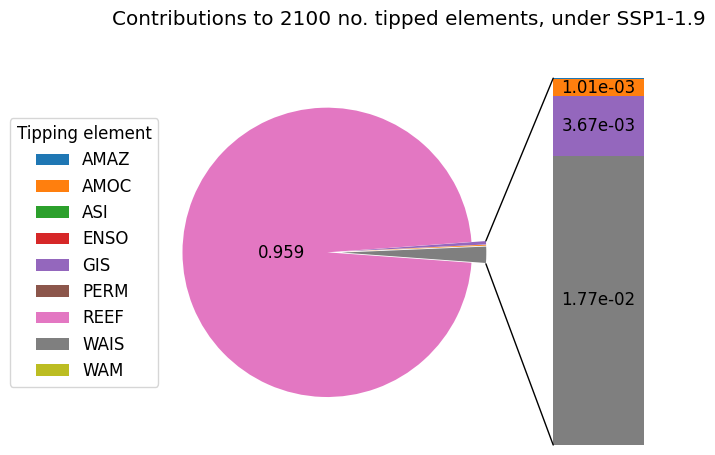

In [181]:
fig,(ax,ax2)=plt.subplots(ncols=2,figsize=(7,5),
                          gridspec_kw=dict(width_ratios=[3,1.5]))
fig.subplots_adjust(wspace=0)

extend = 0.1
explode=np.ones(9)*extend
explode[6]=0
wedges, texts = ax.pie(data,explode=explode,
                       startangle=angle_amaz,
                       labels=['','','','','','',"{:.3f}".format(data[6]),'',''],
                       labeldistance=0.15)
ax.legend(wedges, TEs,
          title="Tipping element",
          loc="center left",
          bbox_to_anchor=(-0.4, 0, 0.5, 1))

prop_cycle = plt.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']
colors = list(colors[:6])+list(colors[7:])
bottom = 1
width = 2
for j, (height, label) in enumerate(zip(data_bar, TEs_bar)):
    bottom -= height
    bc = ax2.bar(0, height, width, bottom=bottom, color=colors[j], label=label)
    if height >= 1e-3:
        ax2.bar_label(bc, labels=["{:.2e}".format(height)], label_type='center')

# ax2.set_title('Age of approvers')
ax2.axis('off')
ax2.set_xlim(- width, width)
# ax2.legend(wedges,TEs,title="Tipping element", loc='center right')

# use ConnectionPatch to draw lines between the two plots
theta1, theta2 = wedges[6].theta1, wedges[6].theta2
center, r = wedges[6].center, wedges[0].r
bar_height = sum(data_bar)

# ax.plot([0,(r+0.1)*np.cos(np.pi / 180 * theta2)],[0,(r+0.1)*np.sin(np.pi / 180 * theta2)])
# draw top connecting line
x = (r+extend) * np.cos(np.pi / 180 * theta2) + center[0]
y = (r+extend) * np.sin(np.pi / 180 * theta2) + center[1]
# con = ConnectionPatch((-width / 2, bar_height), (x,y), 'data',
#                       coordsB=ax2.transData,
#                       xyB=(x, y), coordsB=ax.transData)
con = ConnectionPatch(xyA =(-width / 2, 1-bar_height),
                      coordsA = ax2.transData,
                      xyB =(x, y), 
                      coordsB = ax.transData)
con.set_color([0, 0, 0])
con.set_linewidth(1)
ax2.add_artist(con)

# draw bottom connecting line
x = (r+extend) * np.cos(np.pi / 180 * theta1) + center[0]
y = (r+extend) * np.sin(np.pi / 180 * theta1) + center[1]
con = ConnectionPatch(xyA=(-width / 2, 1), coordsA=ax2.transData,
                      xyB=(x, y), coordsB=ax.transData)
con.set_color([0, 0, 0])
ax2.add_artist(con)
con.set_linewidth(1)
fig.suptitle("Contributions to 2100 no. tipped elements, under SSP1-1.9")

# plt.show()
fig.savefig('../Figures/pie_chart_2100.png',bbox_inches='tight',format='png')

## Long term (Fig. S1)

In [157]:
valmin_str='0001'
Nico_time = False
if Nico_time:
    folder = "../Data/Simulations/TE/Sigmoid/"+valmin_str+"_at_Tmin_NWrtimes/Stat dist over GMST/"
    folder_out = "../Figures/TE (sigmoid)/"+valmin_str+"_at_Tmin_NWrtimes/"
else:
    folder = "../Data/Simulations/TE/Sigmoid/"+valmin_str+"_at_Tmin_WBrtimes/Stat dist over GMST/"
    folder_out = "../Figures/TE (sigmoid)/"+valmin_str+"_at_Tmin_WBrtimes/"
Path(folder_out[:-1]).mkdir(parents=True, exist_ok=True)

D_theory = np.array([np.loadtxt(folder+"D_"+te+".csv") 
                     for i,te in enumerate(TEs)]).transpose((1,2,0))
D_theory_noint = np.array([np.loadtxt(folder+"D_no_interaction_"+te+".csv") 
                           for i,te in enumerate(TEs)]).transpose()
T = np.arange(0,10,step=0.001)
T_lim = np.array(df_AM22['T_lim'].to_list())

ES_mean = D_theory.mean(axis=0).sum(axis=-1)
ES_5 = np.quantile(D_theory.sum(axis=-1),0.05,axis=0)
ES_25= np.quantile(D_theory.sum(axis=-1),0.25,axis=0)
ES_75= np.quantile(D_theory.sum(axis=-1),0.75,axis=0)
ES_95= np.quantile(D_theory.sum(axis=-1),0.95,axis=0)
ES_noint = D_theory_noint.sum(axis=-1)
# %run DataProcessingTE.py
# # Outputs the following:
#     # df_AM22 - processed individual TE data from Armstrong McKay et al 2022
#     # df_W24 - TE-TE interactions from Wunderling et al 2024
#     # df_SSPs - global mean surface temp. anomalies vs pre-industrial (1850-1900). Historical and several SSPs
#         # See scenarios for the list of scenarios 

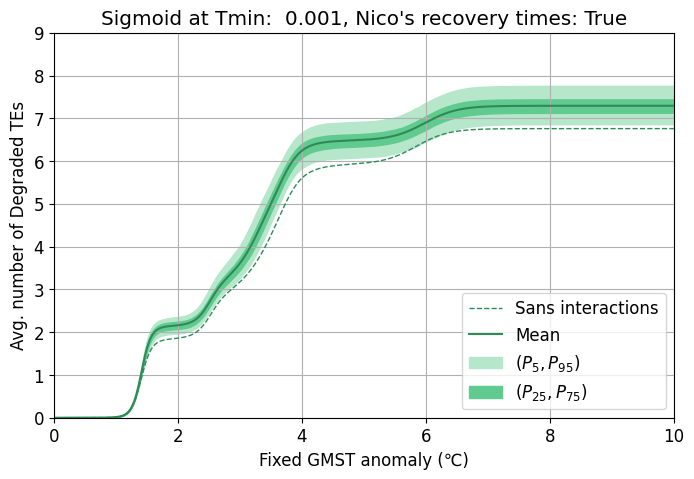

In [152]:
fig,ax = plt.subplots(figsize=(8,5))
theme_col = 'seagreen'

# ax.plot(T,(ES_mean-ES_noint)/ES_noint,
#         color=util.lighten_color(theme_col,1),label='Mean')
# ax.fill_between(T, (ES_5-ES_noint)/ES_noint, (ES_95-ES_noint)/ES_noint,
#                  color=util.lighten_color(theme_col,0.3),
#                  edgecolor=util.lighten_color(theme_col,0.3),
#                  alpha=1,label='$(P_5,P_{95})$')
# ax.fill_between(T, (ES_25-ES_noint)/ES_noint, (ES_75-ES_noint)/ES_noint,
#                  color=util.lighten_color(theme_col,0.65),
#                  edgecolor=util.lighten_color(theme_col,0.65),
#                  alpha=1,label='$(P_{25},P_{75})$')
ax.plot(T,ES_noint,
        c=util.lighten_color(theme_col,1), 
        ls='--',lw=1,label='Sans interactions')
ax.grid()
ax.plot(T,ES_mean,
        color=util.lighten_color(theme_col,1),label='Mean')
ax.fill_between(T, ES_5, ES_95,
                 color=util.lighten_color(theme_col,0.3),
                 edgecolor=util.lighten_color(theme_col,0.3),
                 alpha=1,label='$(P_5,P_{95})$')
ax.fill_between(T, ES_25, ES_75,
                 color=util.lighten_color(theme_col,0.65),
                 edgecolor=util.lighten_color(theme_col,0.65),
                 alpha=1,label='$(P_{25},P_{75})$')
ax.set_ylim([0,9])
ax.set_xlim([0,10])
ax.set_ylabel('Avg. number of Degraded TEs')
ax.set_xlabel('Fixed GMST anomaly (℃)')
legend=plt.legend(loc='lower right')

# fig.savefig(folder_out+'ES_stat_dists_GMST.pdf',format='pdf',dpi=300,bbox_inches='tight')

ax.set_title('Sigmoid at Tmin: '+' 0.'+valmin_str[1:]+", Nico's recovery times: "+str(Nico_times))
fig.savefig("../Figures/"+valmin_str+'NW'+str(Nico_time)+'_ES_gmst.pdf',format='pdf',bbox_inches='tight')

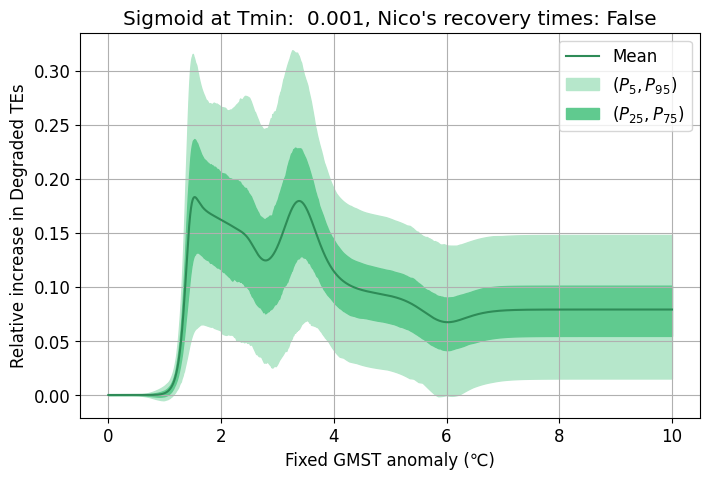

In [158]:
fig,ax = plt.subplots(figsize=(8,5))
theme_col = 'seagreen'

ax.plot(T,(ES_mean-ES_noint)/ES_noint,
        color=util.lighten_color(theme_col,1),label='Mean')
ax.fill_between(T, (ES_5-ES_noint)/ES_noint, (ES_95-ES_noint)/ES_noint,
                 color=util.lighten_color(theme_col,0.3),
                 edgecolor=util.lighten_color(theme_col,0.3),
                 alpha=1,label='$(P_5,P_{95})$')
ax.fill_between(T, (ES_25-ES_noint)/ES_noint, (ES_75-ES_noint)/ES_noint,
                 color=util.lighten_color(theme_col,0.65),
                 edgecolor=util.lighten_color(theme_col,0.65),
                 alpha=1,label='$(P_{25},P_{75})$')

ax.grid()

# ax.plot(T,ES_noint,
#         c=util.lighten_color(theme_col,1), 
#         ls='--',lw=1,label='Sans interactions')
# ax.plot(T,ES_mean,
#         color=util.lighten_color(theme_col,1),label='Mean')
# ax.fill_between(T, ES_5, ES_95,
#                  color=util.lighten_color(theme_col,0.3),
#                  edgecolor=util.lighten_color(theme_col,0.3),
#                  alpha=1,label='$(P_5,P_{95})$')
# ax.fill_between(T, ES_25, ES_75,
#                  color=util.lighten_color(theme_col,0.65),
#                  edgecolor=util.lighten_color(theme_col,0.65),
#                  alpha=1,label='$(P_{25},P_{75})$')
# ax.set_ylim([0,9])
# ax.set_xlim([0,10])
ax.set_ylabel('Relative increase in Degraded TEs')
ax.set_xlabel('Fixed GMST anomaly (℃)')
legend=plt.legend(loc='upper right')

# fig.savefig('../Figures/TE (piecewise)/ES_stat_dists_GMST.pdf',format='pdf',dpi=300,bbox_inches='tight')

ax.set_title('Sigmoid at Tmin: '+' 0.'+valmin_str[1:]+", Nico's recovery times: "+str(Nico_times))
fig.savefig("../Figures/"+valmin_str+'NW'+str(Nico_time)+'_ES_gmst_increase_from_interactions.pdf',format='pdf',bbox_inches='tight')

In [146]:
ES_relinc = (ES_mean-ES_noint)/ES_noint
T[ES_relinc==ES_relinc.max()]

array([1.291])

In [132]:
ES_relinc = (ES_mean-ES_noint)/ES_noint
T[ES_relinc==ES_relinc.max()]

array([1.532])